# Generate topobathy GeoTIFF from GEBCO

Download a regional subset from [GEBCO 2025](https://www.gebco.net/data-products/gridded-bathymetry-data/gebco2025-grid) (CEDA OPeNDAP) at **native grid resolution** (~15 arc-second), save a GeoTIFF, and export the bounding box as an AoI shapefile.

Use this notebook when you do not have local bathymetry yet.

Downstream use:

1. Point `paths.topobathy_file` and `paths.aoi_file` in `Samoa.json` to the outputs below.
2. Continue with `02_Create_Mesh_By_pymesh2d.ipynb`.

Requires network access for the GEBCO download.

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import rioxarray
import xarray as xr
from shapely.geometry import box
from utils.config import resolve

## Parameters

Edit the bounding box and output paths for your case.

In [1]:
# Region of interest (WGS84)
bbox = {
    "lon_min": -173.65,
    "lon_max": -168.75,
    "lat_min": -15.35,
    "lat_max": -12.85,
}

# GEBCO 2025 OPeNDAP endpoint (ice-surface / land elevation)
gebco_url = (
    "https://dap.ceda.ac.uk/thredds/dodsC/bodc/gebco/global/gebco_2025/"
    "ice_surface_elevation/netcdf/GEBCO_2025.nc"
)

In [4]:
# Outputs
output_tif = resolve("inputs/GEBCO/Samoa_GEBCO.tif")
output_aoi = resolve("inputs/GEBCO/Samoa_AoI.shp")

output_tif.parent.mkdir(parents=True, exist_ok=True)
output_aoi.parent.mkdir(parents=True, exist_ok=True)

print(f"GeoTIFF : {output_tif}")
print(f"AoI shp : {output_aoi}")

GeoTIFF : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GEBCO/Samoa_GEBCO.tif
AoI shp : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GEBCO/Samoa_AoI.shp


## Save AoI polygon

Rectangle from the bounding box, written to `inputs/AoI_Polygons/`.

In [5]:
aoi_gdf = gpd.GeoDataFrame(
    {"name": [output_aoi.stem]},
    geometry=[
        box(
            bbox["lon_min"],
            bbox["lat_min"],
            bbox["lon_max"],
            bbox["lat_max"],
        )
    ],
    crs="EPSG:4326",
)

aoi_gdf.to_file(output_aoi)
aoi_gdf

,name,geometry
0,Samoa_AoI,"POLYGON ((-168.75 -15.35, -168.75 -12.85, -173..."


## Download and subset GEBCO

In [6]:
GEBCO = xr.open_dataset(gebco_url)
GEBCO

<xarray.Dataset> Size: 7GB
Dimensions:    (lat: 43200, lon: 86400)
Coordinates:
  * lat        (lat) float64 346kB -90.0 -89.99 -89.99 ... 89.99 89.99 90.0
  * lon        (lon) float64 691kB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
Data variables:
    crs        |S64 64B ...
    elevation  (lat, lon) int16 7GB ...
Attributes: (12/37)
    title:                           The GEBCO_2025 Grid - a continuous terra...
    summary:                         The GEBCO_2025 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    references:                      DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    node_offset:                     1.0
    DODS.strlen:                     0

In [8]:
elev_name = "elevation" if "elevation" in GEBCO else list(GEBCO.data_vars)[0]
print(f"elevation variable: {elev_name}")

# GEBCO latitude is usually descending — slice high to low
lat_slice = slice(bbox["lat_min"], bbox["lat_max"])
lon_slice = slice(bbox["lon_min"], bbox["lon_max"])

gebco_sel = GEBCO.sel(lon=lon_slice, lat=lat_slice)
gebco_sel

elevation variable: elevation


<xarray.Dataset> Size: 1MB
Dimensions:    (lat: 600, lon: 1176)
Coordinates:
  * lat        (lat) float64 5kB -15.35 -15.34 -15.34 ... -12.86 -12.86 -12.85
  * lon        (lon) float64 9kB -173.6 -173.6 -173.6 ... -168.8 -168.8 -168.8
Data variables:
    crs        |S64 64B ...
    elevation  (lat, lon) int16 1MB ...
Attributes: (12/37)
    title:                           The GEBCO_2025 Grid - a continuous terra...
    summary:                         The GEBCO_2025 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    references:                      DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    node_offset:                     1.0
    DODS.strlen:                     0

## Write GeoTIFF (native GEBCO resolution)

In [9]:
gebco_raster = (
    gebco_sel[elev_name]
    .rio.set_spatial_dims(x_dim="lon", y_dim="lat", inplace=False)
    .rio.write_crs("EPSG:4326", inplace=False)
)

gebco_raster.rio.to_raster(output_tif)
print(f"Wrote {output_tif}")
print(f"CRS: {gebco_raster.rio.crs}")
print(f"Resolution (deg): {gebco_raster.rio.resolution()}")
print(f"Shape: {gebco_raster.shape}")

Wrote /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GEBCO/Samoa_GEBCO.tif
CRS: EPSG:4326
Resolution (deg): (0.004166666666666674, 0.004166666666666649)
Shape: (600, 1176)


## Quick preview

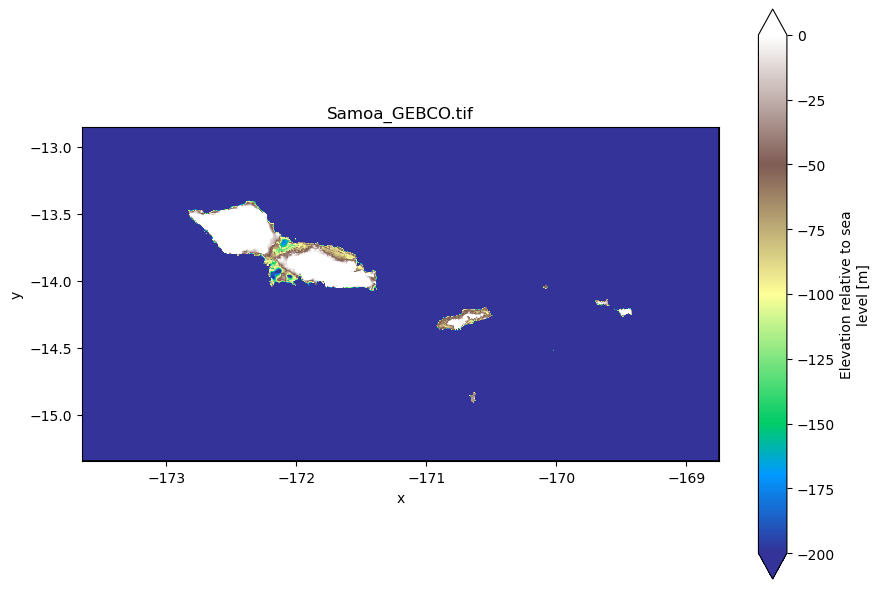

In [10]:
topobathy = rioxarray.open_rasterio(output_tif).squeeze(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
topobathy.plot.imshow(ax=ax, vmin=-200, vmax=0, cmap="terrain")
aoi_gdf.boundary.plot(ax=ax, color="black", linewidth=1.2)
ax.set_title(output_tif.name)
fig.tight_layout()
plt.show()

## Next step

Update `Samoa.json` if you changed output paths:

```json
"paths": {
    "aoi_file": "inputs/AoI_Polygons/Samoa_AoI.shp",
    "topobathy_file": "inputs/GRID/Samoa_gebco.tif"
}
```

Then run `02_Create_Mesh_By_pymesh2d.ipynb`.